# Phase D - Python/Pandas Analysis

## Restaurant Performance, Customer Preference & Online Ordering Analytics

#### This project focuses on analyzing restaurant, customer, cuisine, and order data to identify important business patterns and trends. The analysis examines restaurant distribution, customer ratings, votes, cuisine preferences, online ordering, order values, delivery times, and revenue performance.The project aims to transform raw data into meaningful insights that can help understand restaurant performance, customer behavior, and revenue trends.

# 1.Import Libraries

In [107]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 2.Load the Five Raw datasets

In [3]:
ordr=pd.read_csv(r"F:\DA\Internship Raw data\orders.csv")
res=pd.read_csv(r"F:\DA\Internship Raw data\restaurants.csv")
loc=pd.read_csv(r"F:\DA\Internship Raw data\locations.csv")
cust=pd.read_csv(r"F:\DA\Internship Raw data\customers.csv")
cuis=pd.read_csv(r"F:\DA\Internship Raw data\cuisines.csv")

# 3.To Inspect the structure

In [4]:
ordr.head()

,Order_ID,Restaurant_ID,Customer_ID,Order_Date,Order_Value,Delivery_Time,Discount,Delivery_Fee,Order_Status,Payment_Method
0,O000001,R0074,CU04115,2025-02-20,713.26,31,0.00,40,Completed,Card
1,O000002,R0072,CU04185,2025-03-24,931.79,40,0.00,50,Completed,Card
2,O000003,R0401,CU01997,2025-03-22,394.73,28,39.47,40,Cancelled,Wallet
3,O000004,R0284,CU00947,2025-02-22,912.48,26,45.62,60,Completed,Wallet
4,O000005,R0463,CU00584,2025-08-11,871.37,30,43.57,60,Completed,Cash


In [5]:
res.head()

,Restaurant_ID,Restaurant_Name,Location_ID,Cuisine_ID,Rating,Votes,Average_Cost,Online_Order,Table_Booking,Restaurant_Type,Established_Year,Delivery_Time,Delivery_Rating,Is_Active
0,R0001,Continental Fine 1,L024,C013,3.5,694,700,Yes,No,Fine Dining,2016,42,3.3,Yes
1,R0002,Biryani Fine 2,L024,C007,4.4,215,350,Yes,No,Fine Dining,2023,44,3.9,Yes
2,R0003,Italian Fine 3,L018,C005,3.3,67,300,Yes,No,Fine Dining,2007,39,4.2,Yes
3,R0004,North Indian Cafe 4,L024,C002,4.0,663,500,No,Yes,Cafe,2004,51,3.0,Yes
4,R0005,Seafood Quick 5,L030,C017,4.5,628,800,Yes,Yes,Quick Service,2004,37,4.1,Yes


In [6]:
loc.head()

,Location_ID,Location,City,State,Region,Population_Category,Avg_Rent_Index
0,L001,Koramangala,Bengaluru,Karnataka,South,Medium,155.6
1,L002,Indiranagar,Bengaluru,Karnataka,South,High,123.9
2,L003,Whitefield,Bengaluru,Karnataka,South,Low,84.0
3,L004,Jayanagar,Bengaluru,Karnataka,South,Low,148.0
4,L005,HSR Layout,Bengaluru,Karnataka,South,Medium,133.7


In [7]:
cust.head()

,Customer_ID,Customer_Age,Gender,City,Signup_Date,Customer_Type,Total_Orders,Average_Order_Value
0,CU00001,41,Female,Hyderabad,2025-11-22,Regular,15,426.47
1,CU00002,48,Female,Kolkata,2025-12-27,Regular,9,1059.51
2,CU00003,20,Female,Kolkata,2025-05-27,New,10,1093.78
3,CU00004,33,Other,Kochi,2023-06-20,Regular,17,527.28
4,CU00005,47,Male,Delhi,2023-01-14,Regular,7,795.45


In [8]:
cuis.head()

,Cuisine_ID,Cuisine,Cuisine_Category,Vegetarian_Friendly
0,C001,Indian,Indian,Yes
1,C002,North Indian,Indian,Yes
2,C003,South Indian,Indian,Yes
3,C004,Chinese,Asian,Yes
4,C005,Italian,Continental,Yes


### Dataset Dimensions

In [9]:
print("Orders    :",ordr.shape)
print("Restaurant:",res.shape)
print("location  :",loc.shape)
print("Customers :",cust.shape)
print("Cuisines  :",cuis.shape)

Orders    : (20020, 10)
Restaurant: (508, 14)
location  : (48, 7)
Customers : (5000, 8)
Cuisines  : (20, 4)


### Dataset Information

In [10]:
ordr.info()

<class 'pandas.DataFrame'>
RangeIndex: 20020 entries, 0 to 20019
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Order_ID        20020 non-null  str    
 1   Restaurant_ID   20020 non-null  str    
 2   Customer_ID     20020 non-null  str    
 3   Order_Date      20020 non-null  str    
 4   Order_Value     20000 non-null  float64
 5   Delivery_Time   20020 non-null  int64  
 6   Discount        20020 non-null  float64
 7   Delivery_Fee    20020 non-null  int64  
 8   Order_Status    20020 non-null  str    
 9   Payment_Method  20020 non-null  str    
dtypes: float64(2), int64(2), str(6)
memory usage: 1.5 MB


In [11]:
res.info()

<class 'pandas.DataFrame'>
RangeIndex: 508 entries, 0 to 507
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Restaurant_ID     508 non-null    str    
 1   Restaurant_Name   502 non-null    str    
 2   Location_ID       508 non-null    str    
 3   Cuisine_ID        508 non-null    str    
 4   Rating            496 non-null    float64
 5   Votes             508 non-null    int64  
 6   Average_Cost      508 non-null    int64  
 7   Online_Order      508 non-null    str    
 8   Table_Booking     508 non-null    str    
 9   Restaurant_Type   508 non-null    str    
 10  Established_Year  508 non-null    int64  
 11  Delivery_Time     508 non-null    int64  
 12  Delivery_Rating   508 non-null    float64
 13  Is_Active         508 non-null    str    
dtypes: float64(2), int64(4), str(8)
memory usage: 55.7 KB


In [12]:
loc.info()

<class 'pandas.DataFrame'>
RangeIndex: 48 entries, 0 to 47
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Location_ID          48 non-null     str    
 1   Location             48 non-null     str    
 2   City                 48 non-null     str    
 3   State                48 non-null     str    
 4   Region               48 non-null     str    
 5   Population_Category  48 non-null     str    
 6   Avg_Rent_Index       48 non-null     float64
dtypes: float64(1), str(6)
memory usage: 2.8 KB


In [13]:
cust.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Customer_ID          5000 non-null   str    
 1   Customer_Age         5000 non-null   int64  
 2   Gender               5000 non-null   str    
 3   City                 5000 non-null   str    
 4   Signup_Date          5000 non-null   str    
 5   Customer_Type        5000 non-null   str    
 6   Total_Orders         5000 non-null   int64  
 7   Average_Order_Value  5000 non-null   float64
dtypes: float64(1), int64(2), str(5)
memory usage: 312.6 KB


In [14]:
cuis.info()

<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 4 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Cuisine_ID           20 non-null     str  
 1   Cuisine              20 non-null     str  
 2   Cuisine_Category     20 non-null     str  
 3   Vegetarian_Friendly  20 non-null     str  
dtypes: str(4)
memory usage: 772.0 bytes


# 4.Missing Values Analysis

In [15]:
# To find the missing values in each dataset

print("Orders:")
print(ordr.isnull().sum())

print("\nRestaurant:")
print(res.isnull().sum())

print("\nLocation:")
print(loc.isnull().sum())

print("\nCustomers:")
print(cust.isnull().sum())

print("\nCuisines:")
print(cuis.isnull().sum())

Orders:
Order_ID           0
Restaurant_ID      0
Customer_ID        0
Order_Date         0
Order_Value       20
Delivery_Time      0
Discount           0
Delivery_Fee       0
Order_Status       0
Payment_Method     0
dtype: int64

Restaurant:
Restaurant_ID        0
Restaurant_Name      6
Location_ID          0
Cuisine_ID           0
Rating              12
Votes                0
Average_Cost         0
Online_Order         0
Table_Booking        0
Restaurant_Type      0
Established_Year     0
Delivery_Time        0
Delivery_Rating      0
Is_Active            0
dtype: int64

Location:
Location_ID            0
Location               0
City                   0
State                  0
Region                 0
Population_Category    0
Avg_Rent_Index         0
dtype: int64

Customers:
Customer_ID            0
Customer_Age           0
Gender                 0
City                   0
Signup_Date            0
Customer_Type          0
Total_Orders           0
Average_Order_Value    0
dtype: int

In [ ]:
# To find the percentage of missing values in each dataset
print("Missing ordr"= (ordr.isnull().sum() / len(ordr)) * 100)
print("Missing res"= (ordr.isnull().sum() / len(ordr)) * 100)
print("Missing loc"= (ordr.isnull().sum() / len(ordr)) * 100)
print("Missing cust"= (ordr.isnull().sum() / len(ordr)) * 100)
print("Missing cuis"= (ordr.isnull().sum() / len(ordr)) * 100)

In [28]:
# Remove rows with missing order value
ordr=ordr.dropna(subset=["Order_Value"])

#fill the missing restaurant names with unknown
res["Restaurant_Name"]=res["Restaurant_Name"].fillna("Unknown")

#fill missing rating values with mean
res["Rating"]=res["Rating"].fillna(res["Rating"].mean())

print("Order Dataset Rows:",len(ordr))
print("Missing Order values:",ordr["Order_Value"].isna().sum())
print("Missing res['Restaurant_Name']=",res['Restaurant_Name'].isnull().sum())
print (len(res[res['Restaurant_Name']=="Unknown"]))
print("Missing Rating:",res["Rating"].isna().sum())      

Order Dataset Rows: 19980
Missing Order values: 0
Missing res['Restaurant_Name']= 0
6
Missing Rating: 0


# 5.Duplicate value Analysis

In [18]:
#To find duplicate values in each dataset 
print("Orders duplicates:", ordr.duplicated().sum())
print("Restaurant duplicates:", res.duplicated().sum())
print("Location duplicates:", loc.duplicated().sum())
print("Customers duplicates:", cust.duplicated().sum())
print("Cuisines duplicates:", cuis.duplicated().sum())

Orders duplicates: 20
Restaurant duplicates: 8
Location duplicates: 0
Customers duplicates: 0
Cuisines duplicates: 0


In [17]:
# remove duplicate order_IDs
ordr=ordr.drop_duplicates()

#remove duplicate Restaurant_IDs
res=res.drop_duplicates()

print("Orders:",len(ordr))
print("Restaurant:",len(res))


Orders: 19980
Restaurant: 500


# 6.categorical/text inconsistencies

In [29]:
res['Online_Order'].unique()

<StringArray>
['Yes', 'No', 'yes']
Length: 3, dtype: str

In [30]:
# To standardize the Online order column
res['Online_Order'] = res['Online_Order'].str.title()

# 7.Data Type Validation

In [23]:
print("orders:")
print(ordr.dtypes)

print("\nRestaurants:")
print(res.dtypes)

print("\nLocation:")
print(loc.dtypes)

print("\nCustomers:")
print(cust.dtypes)

print("\nCuisines:")
print(cuis.dtypes)

orders:
Order_ID              str
Restaurant_ID         str
Customer_ID           str
Order_Date            str
Order_Value       float64
Delivery_Time       int64
Discount          float64
Delivery_Fee        int64
Order_Status          str
Payment_Method        str
dtype: object
Restaurants:
Restaurant_ID           str
Restaurant_Name         str
Location_ID             str
Cuisine_ID              str
Rating              float64
Votes                 int64
Average_Cost          int64
Online_Order            str
Table_Booking           str
Restaurant_Type         str
Established_Year      int64
Delivery_Time         int64
Delivery_Rating     float64
Is_Active               str
dtype: object
Location:
Location_ID                str
Location                   str
City                       str
State                      str
Region                     str
Population_Category        str
Avg_Rent_Index         float64
dtype: object
Customers:
Customer_ID                str
Customer_Age    

In [ ]:
####### Here 2 columns have the date details and to covert its datatype to datetime format

In [32]:
ordr['Order_Date'] = pd.to_datetime(ordr['Order_Date'])

cust['Signup_Date'] = pd.to_datetime(cust['Signup_Date'])

# 8. Invalid Numerical Values

In [38]:
print("Negative Ratings:", (res['Rating'] < 0).sum())
print("Negative Votes:", (res['Votes'] < 0).sum())
print("Negative Average Cost:", (res['Average_Cost'] < 0).sum())
print("Negative Delivery Time:", (res['Delivery_Time'] < 0).sum())
print("Negative Order Values:", (ordr['Order_Value'] < 0).sum())

Negative Ratings: 0
Negative Votes: 0
Negative Average Cost: 5
Negative Delivery Time: 0
Negative Order Values: 0


In [39]:
# Replace invalid negative average cost value with positive value
res['Average_Cost'] = res['Average_Cost'].replace(-100, 100)

# 9.Dataset Merging

In [40]:
analysis_df = ordr.merge(
    cust,
    on='Customer_ID',
    how='left'
)

analysis_df = analysis_df.merge(
    res,
    on='Restaurant_ID',
    how='left'
)

analysis_df = analysis_df.merge(
    loc,
    on='Location_ID',
    how='left'
)

analysis_df = analysis_df.merge(
    cuis,
    on='Cuisine_ID',
    how='left'
)

In [41]:
analysis_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19980 entries, 0 to 19979
Data columns (total 39 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Order_ID             19980 non-null  str           
 1   Restaurant_ID        19980 non-null  str           
 2   Customer_ID          19980 non-null  str           
 3   Order_Date           19980 non-null  datetime64[us]
 4   Order_Value          19980 non-null  float64       
 5   Delivery_Time_x      19980 non-null  int64         
 6   Discount             19980 non-null  float64       
 7   Delivery_Fee         19980 non-null  int64         
 8   Order_Status         19980 non-null  str           
 9   Payment_Method       19980 non-null  str           
 10  Customer_Age         19980 non-null  int64         
 11  Gender               19980 non-null  str           
 12  City_x               19980 non-null  str           
 13  Signup_Date          19980 non-null  datet

# 10.Descriptive Statistics

In [42]:
print("Restaurant Statistics")
print(res[
    ['Rating', 'Votes', 'Average_Cost', 'Delivery_Time', 'Delivery_Rating']
].describe())

print("\nOrder Statistics")
print(ordr[
    ['Order_Value', 'Delivery_Time', 'Discount', 'Delivery_Fee']
].describe())

print("\nCustomer Statistics")
print(cust[
    ['Customer_Age', 'Total_Orders', 'Average_Order_Value']
].describe())

print("\nLocation Statistics")
print(loc[
    ['Avg_Rent_Index']
].describe())

Restaurant Statistics
           Rating        Votes  Average_Cost  Delivery_Time  Delivery_Rating
count  500.000000   500.000000    500.000000     500.000000       500.000000
mean     3.661997   375.030000    692.700000      34.286000         3.728600
std      0.563469   473.664494    333.247382       9.974125         0.504332
min      1.900000    17.000000    100.000000      15.000000         2.000000
25%      3.300000   114.000000    450.000000      27.000000         3.400000
50%      3.600000   220.000000    600.000000      34.000000         3.700000
75%      4.100000   465.250000    850.000000      41.000000         4.100000
max      4.900000  4882.000000   2750.000000      63.000000         5.000000

Order Statistics
        Order_Value  Delivery_Time      Discount  Delivery_Fee
count  19980.000000   19980.000000  19980.000000  19980.000000
mean     751.061817      34.672973     50.987188     40.015516
std      436.863816       9.764347     61.382650     14.106158
min      100.00

# 11.Outlier Analysis

###### Outliers were identified using the IQR method

## 11.1 Rating Outliers

In [44]:
Q1 = res['Rating'].quantile(0.25)
Q3 = res['Rating'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

rating_outliers = res[
    (res['Rating'] < lower_limit) |
    (res['Rating'] > upper_limit)
]

print("Q1:",Q1)
print("Q3:",Q3)
print("IQR:",IQR)
print("Lower Limit:",lower_limit)
print("Upper Limit:",upper_limit)
print("Number of Rating outliers:", len(rating_outliers))

Q1: 3.3
Q3: 4.1
IQR: 0.7999999999999998
Lower Limit: 2.1
Upper Limit: 5.299999999999999
Number of Rating outliers: 2


In [50]:
rating_outliers[['Restaurant_ID','Restaurant_Name','Rating']]

,Restaurant_ID,Restaurant_Name,Rating
300,R0301,Seafood Casual 301,2.0
312,R0313,Cafe Cafe 313,1.9


## 11.2 Average cost Outliers

In [48]:
Q1 = res['Average_Cost'].quantile(0.25)
Q3 = res['Average_Cost'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

Average_Cost_outliers = res[
    (res['Average_Cost'] < lower_limit) |
    (res['Average_Cost'] > upper_limit)
]

print("Q1:",Q1)
print("Q3:",Q3)
print("IQR:",IQR)
print("Lower Limit:",lower_limit)
print("Upper Limit:",upper_limit)
print("Number of  outliers:", len( Average_Cost_outliers))

Q1: 450.0
Q3: 850.0
IQR: 400.0
Lower Limit: -150.0
Upper Limit: 1450.0
Number of  outliers: 10


In [49]:
Average_Cost_outliers[['Restaurant_ID','Restaurant_Name','Average_Cost']]

,Restaurant_ID,Restaurant_Name,Average_Cost
34,R0035,Chinese Bakery 35,1600
97,R0098,Desserts Casual 98,1500
114,R0115,Biryani Casual 115,1600
232,R0233,South Indian Casual 233,2250
254,R0255,Mughlai Casual 255,2000
327,R0328,Fast Food Food 328,1550
348,R0349,Street Food Casual 349,1650
370,R0371,BBQ Food 371,2750
428,R0429,Mexican Food 429,1950
471,R0472,Italian Food 472,1600


## 11.3 Votes outlier Analysis

In [51]:
Q1 = res['Votes'].quantile(0.25)
Q3 = res['Votes'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

Votes_outliers = res[
    (res['Votes'] < lower_limit) |
    (res['Votes'] > upper_limit)
]

print("Q1:",Q1)
print("Q3:",Q3)
print("IQR:",IQR)
print("Lower Limit:",lower_limit)
print("Upper Limit:",upper_limit)
print("Number of  outliers:", len( Votes_outliers))

Q1: 114.0
Q3: 465.25
IQR: 351.25
Lower Limit: -412.875
Upper Limit: 992.125
Number of  outliers: 39


In [52]:
Votes_outliers[['Restaurant_ID','Restaurant_Name','Votes']]

,Restaurant_ID,Restaurant_Name,Votes
7,R0008,Continental Quick 8,1724
21,R0022,Fast Food Bakery 22,1075
23,R0024,Korean Quick 24,1360
33,R0034,Biryani Food 34,1062
117,R0118,Indian Casual 118,1181
123,R0124,Fast Food Casual 124,1048
131,R0132,North Indian Fine 132,1269
133,R0134,Cafe Casual 134,1257
157,R0158,Japanese Casual 158,1024
160,R0161,Continental Cafe 161,1063


## 11.4 Order Value Outlier Analysis

In [54]:
Q1 = ordr['Order_Value'].quantile(0.25)
Q3 = ordr['Order_Value'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

Order_Value_outliers = ordr[
    (ordr['Order_Value'] < lower_limit) |
    (ordr['Order_Value'] > upper_limit)
]

print("Q1:",Q1)
print("Q3:",Q3)
print("IQR:",IQR)
print("Lower Limit:",lower_limit)
print("Upper Limit:",upper_limit)
print("Number of  outliers:", len( Order_Value_outliers))

Q1: 451.2275
Q3: 935.3075
IQR: 484.08
Lower Limit: -274.8925
Upper Limit: 1661.4275
Number of  outliers: 875


## 11.5 Delivery Time Outlier Analysis

In [55]:
Q1 = ordr['Delivery_Time'].quantile(0.25)
Q3 = ordr['Delivery_Time'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

Delivery_Time_outliers = ordr[
    (ordr['Delivery_Time'] < lower_limit) |
    (ordr['Delivery_Time'] > upper_limit)
]

print("Q1:",Q1)
print("Q3:",Q3)
print("IQR:",IQR)
print("Lower Limit:",lower_limit)
print("Upper Limit:",upper_limit)
print("Number of  outliers:", len(Delivery_Time_outliers))

Q1: 28.0
Q3: 41.0
IQR: 13.0
Lower Limit: 8.5
Upper Limit: 60.5
Number of  outliers: 99


In [ ]:
###### The analysis identified limited outliers in Rating, Average cost and voting, while order value has the highest number of outliers. Delivery time also showed a small number of potential outliers. 

# 12.Group By Analysis

## 12.1 Number of Restaurant by location

In [86]:
rest_loc=res.merge(loc[["Location_ID","Location"]],
                              on="Location_ID",
                              how="left" 
)

restaurant_count_by_location=(
    rest_loc.groupby('Location')['Restaurant_ID']
        .count()
        .sort_values(ascending=False)
)

restaurant_count_by_location

Location
Koregaon Park       18
Fort Kochi          17
Salt Lake           16
Dwarka              16
Gariahat            15
Hinjewadi           15
Alipore             15
Kothrud             13
Gachibowli          13
New Town            13
Saket               13
Powai               13
Begumpet            12
Madhapur            12
Lower Parel         12
Bandra              12
Nungambakkam        11
Anna Nagar          11
Connaught Place     11
Park Street         11
Kakkanad            11
Vasant Kunj         11
Wakad               11
Jayanagar           11
Adyar               10
Indiranagar         10
HSR Layout          10
Andheri             10
OMR                  9
Borivali             9
Electronic City      9
Viman Nagar          9
Velachery            9
Kaloor               8
Rohini               8
Dadar                8
Banjara Hills        8
Kukatpally           8
Hauz Khas            8
Jubilee Hills        8
T Nagar              7
Whitefield           7
Ballygunge           7
Ba

## 12.2 Average Rating By Location

In [88]:
average_rating_by_location=(
    rest_loc.groupby('Location')['Rating']
        .mean()
        .sort_values(ascending=False)
)

average_rating_by_location

Location
Velachery           4.277778
Panampilly Nagar    4.260000
Anna Nagar          3.978776
Begumpet            3.908333
OMR                 3.900000
Baner               3.900000
Edappally           3.883333
Saket               3.871774
Kaloor              3.870817
New Town            3.830769
Gachibowli          3.817928
Hauz Khas           3.812500
Rohini              3.812500
Whitefield          3.800000
Kukatpally          3.800000
Alipore             3.793333
Bandra              3.766667
Gariahat            3.726667
Electronic City     3.711111
Kakkanad            3.709091
Madhapur            3.708333
Wakad               3.681818
Jayanagar           3.681818
Ballygunge          3.680933
HSR Layout          3.680000
Koregaon Park       3.675918
Vyttila             3.650000
Indiranagar         3.630000
Nungambakkam        3.609091
Dwarka              3.606250
Connaught Place     3.600000
Lower Parel         3.600000
Viman Nagar         3.596281
Kothrud             3.592308
Boriv

## 12.3 Restaurant count By Cuisine

In [91]:
rest_cuis=res.merge(cuis[["Cuisine_ID","Cuisine"]],
                    on="Cuisine_ID",
                    how="left"
                   )

restaurant_count_by_cuisine=(
    rest_cuis.groupby('Cuisine')['Restaurant_ID']
        .count()
        .sort_values(ascending=False)
)

restaurant_count_by_cuisine

Cuisine
Thai            35
Fast Food       34
Korean          31
Biryani         30
Seafood         29
Mexican         27
Chinese         27
Cafe            26
Continental     26
BBQ             25
Bakery          24
Street Food     24
Kerala          23
North Indian    22
Japanese        22
Desserts        22
South Indian    21
Indian          19
Mughlai         19
Italian         14
Name: Restaurant_ID, dtype: int64

## 12.4 Average Rating By cuisine

In [92]:
avg_rating_by_cuisine=(
    rest_cuis.groupby('Cuisine')['Rating']
        .mean()
        .sort_values(ascending=False)
)

avg_rating_by_cuisine

Cuisine
Biryani         3.867769
BBQ             3.832000
Fast Food       3.782353
Continental     3.744867
South Indian    3.742857
Desserts        3.709091
Indian          3.698239
Korean          3.690323
Street Food     3.673606
Chinese         3.666667
Thai            3.657143
North Indian    3.650000
Japanese        3.640909
Seafood         3.628726
Mexican         3.556780
Kerala          3.537675
Mughlai         3.531579
Cafe            3.494867
Bakery          3.490272
Italian         3.457143
Name: Rating, dtype: float64

## 12.5 Average Rating by Restaurant type

In [93]:
avg_rating_by_rest_type=(
    res.groupby('Restaurant_Type')['Rating']
        .mean()
        .sort_values(ascending=False)
)

avg_rating_by_rest_type

Restaurant_Type
Food Court       3.776019
Fine Dining      3.722642
Quick Service    3.691663
Cafe             3.659719
Casual Dining    3.604164
Bakery           3.557930
Name: Rating, dtype: float64

## 12.6 Average Order Value By Customer Type

In [94]:
avg_order_by_cust_type=(
    cust.groupby('Customer_Type')['Average_Order_Value']
        .mean()
        .sort_values(ascending=False)
)

avg_order_by_cust_type

Customer_Type
Premium    682.987075
New        679.835380
Regular    675.506530
Name: Average_Order_Value, dtype: float64

## 12.7 Average Rating by Online Ordering 

In [95]:
online_ordering_rating=(
    res.groupby('Online_Order')['Rating']
        .mean()
)

online_ordering_rating

Online_Order
No     3.632630
Yes    3.680149
Name: Rating, dtype: float64

# Relationship Analysis Between Important variables

In [96]:
# average cost vs rating

cost_rating_correlation=res['Average_Cost'].corr(res['Rating'])
print("cost_rating_correlation:",round(cost_rating_correlation,3))

np.float64(-0.06752560244775142)

In [ ]:
##### This indicates a very weak negative relationship. This suggests that restaurant cost has little linear association with customer ratings, so higher cost restaurants do not necessarily receive higher ratings.

In [98]:
# Rating Vs Votes

vote_rating_correlation=res['Rating'].corr(res['Votes'])
print("vote_rating_correlation:",round(vote_rating_correlation,3))

0.01414268231012088


In [ ]:
# This indicates a negligible positive relationsip. This suggest that the number of votes received by a restaurant has little linear association with its rating 

In [101]:
# Order value Vs Order delievery Time

ord_value_time_correlation=ordr['Order_Value'].corr(ordr['Delivery_Time'])
print("ord_value_time_correlation:",round(ord_value_time_correlation,3))

ord_value_time_correlation: -0.004


In [ ]:
# This indicates an almost negligible relationship. this suggest that the amount spent on an order has virtually no linear association with delivery time

In [102]:
# Discount Vs Order Value

ord_value_discount_correlation=ordr['Discount'].corr(ordr['Order_Value'])
print("ord_value_discount_correlation:",round(ord_value_discount_correlation,3))

ord_value_discount_correlation: 0.49


In [ ]:
# This indicates a moderate positive relationship. This suggests that orders with higher values tend to have higher discounts in this dataset.

# 13.Visual Analysis

## 13.1 Restaurant Count by City/Location

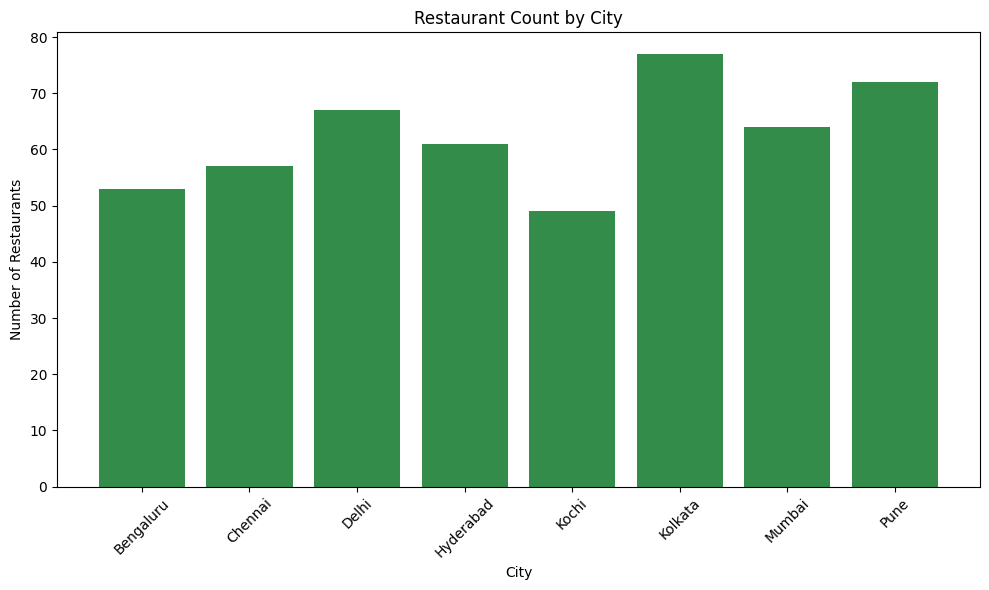

In [108]:
restaurant_location = res.merge(
    loc[['Location_ID', 'City']],
    on='Location_ID',
    how='left'
)

restaurant_count = restaurant_location.groupby('City')['Restaurant_ID'].count()

plt.figure(figsize=(10, 6))
plt.bar(restaurant_count.index, restaurant_count.values, color="#348c4b")

plt.xlabel('City')
plt.ylabel('Number of Restaurants')
plt.title('Restaurant Count by City')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## 13.2 Average Rating by Location

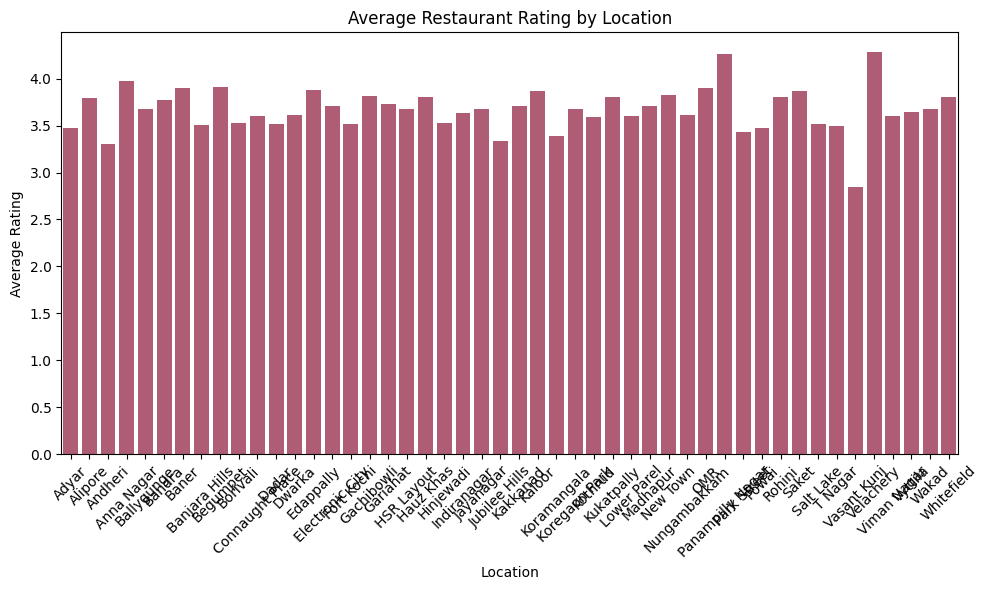

In [111]:
restaurant_loc = res.merge(
    loc[['Location_ID', 'Location']],
    on='Location_ID',
    how='left'
)

average_rating = restaurant_loc.groupby('Location')['Rating'].mean().round(2)

plt.figure(figsize=(10, 6))
sns.barplot(x=average_rating.index, y=average_rating.values,color="#bd4f6e")

plt.xlabel('Location')
plt.ylabel('Average Rating')
plt.title('Average Restaurant Rating by Location')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## 13.3 Rating Distribution

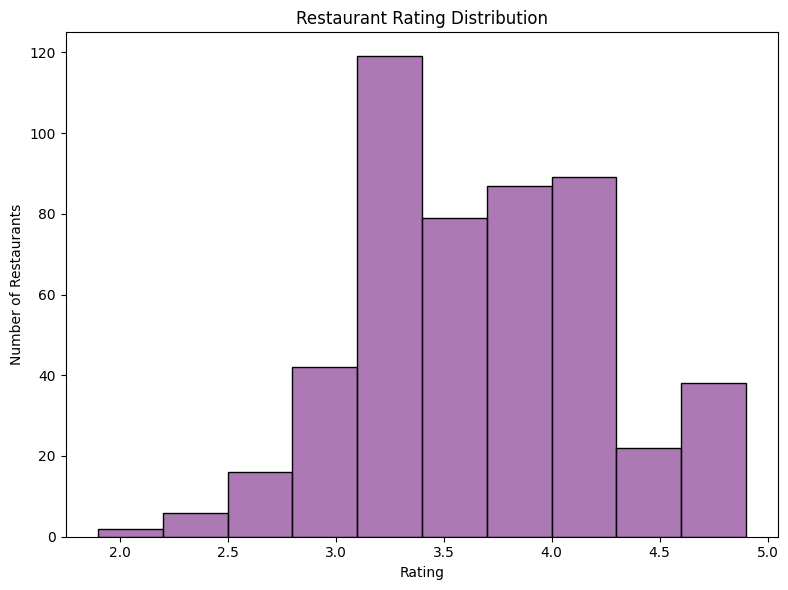

In [112]:
plt.figure(figsize=(8, 6))

sns.histplot(res['Rating'], bins=10, color="#914c9c", edgecolor="black")

plt.xlabel('Rating')
plt.ylabel('Number of Restaurants')
plt.title('Restaurant Rating Distribution')

plt.tight_layout()
plt.show()

## 13.4 Rating versus Votes

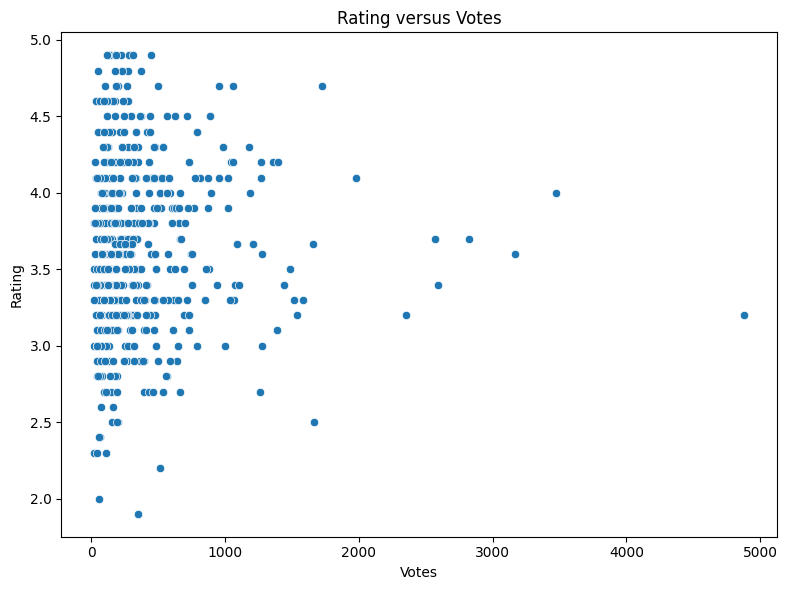

In [113]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=res['Votes'],
    y=res['Rating']
)

plt.xlabel('Votes')
plt.ylabel('Rating')
plt.title('Rating versus Votes')

plt.tight_layout()
plt.show()

## 13.5 Monthly Completed-Order Revenue

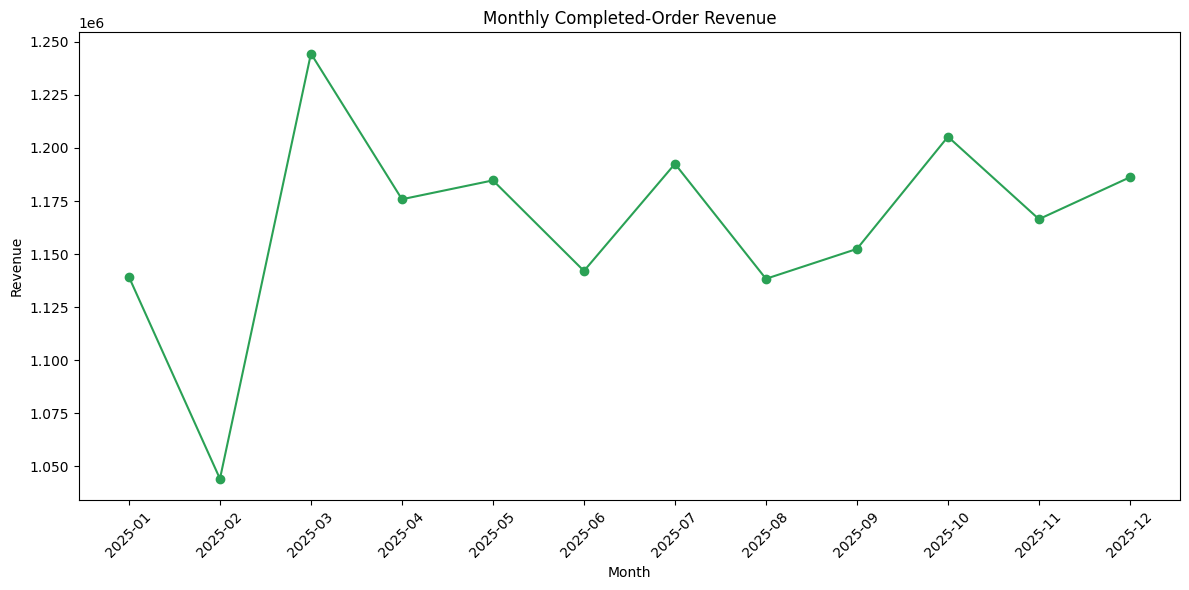

In [116]:
ordr['Order_Date'] = pd.to_datetime(ordr['Order_Date'])

completed_orders = ordr[
    ordr['Order_Status'].str.strip().str.lower() == 'completed'
].copy()

completed_orders['Month'] = completed_orders['Order_Date'].dt.to_period('M')

monthly_revenue = completed_orders.groupby('Month')['Order_Value'].sum()

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_revenue.index.astype(str),
    monthly_revenue.values,
    marker='o',color="#2aa155"
)

plt.xlabel('Month')
plt.ylabel('Revenue')
plt.title('Monthly Completed-Order Revenue')

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## 13.6 Online Ordering versus Rating

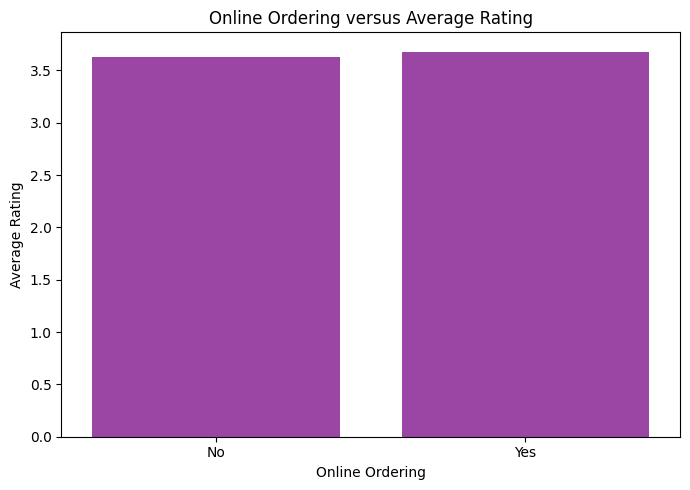

In [118]:
online_rating = res.groupby('Online_Order')['Rating'].mean()

plt.figure(figsize=(7, 5))

sns.barplot(x=online_rating.index, y=online_rating.values, color="#a835b5")

plt.xlabel('Online Ordering')
plt.ylabel('Average Rating')
plt.title('Online Ordering versus Average Rating')

plt.tight_layout()
plt.show()

# Key Insights

##### · Restaurant presence varies across locations: Koregaon Park has the highest number of restaurants (18), while Vyttila has the lowest(2), resulting in a difference of 16 restaurants.
##### . Average ratings vary considerably across locations: Velachery records the highest average rating (4.28), while Vasant Kunj records the lowest (2.85), with a difference of 1.43 rating points.
##### . Thai is the most represented cuisine: Thai has the highest number of restaurants (35), followed by Fast Food (34) and Korean (31), while Italian has the lowest representation (14).
##### . Biryani has the highest average rating among cuisines: Biryani records the highest average rating (3.87), followed by BBQ (3.83) and Fast Food (3.78), while Italian records the lowest (3.46), resulting in a 0.41-point difference between the highest and lowest averages.
##### · Average ratings are relatively consistent across restaurant types: Food Court has the highest average rating (3.78), followed by Fine Dining (3.72) and Quick Service (3.69), while Bakery has the lowest (3.56). The difference between the highest and lowest averages is 0.22 points.
##### · Average order value is similar across customer types: Premium customers have the highest average order value (₹682.99), followed by New customers (₹679.84) and Regular customers (₹675.51). The difference between the highest and lowest averages is only ₹7.48.
##### · Online ordering is associated with only a small difference in average ratings: Restaurants offering online ordering have an average rating of 3.68, compared with 3.63 for restaurants without online ordering, a difference of just 0.05 points.
##### · Discount and Order Value show a moderate positive relationship: The correlation between Discount and Order Value is 0.49, while Average Cost vs Rating (-0.068), Rating vs Votes (0.014), and Order Value vs Order Delivery Time (-0.004) show very weak or negligible linear relationships.